# Decision Tree Classifier
**Name:** GUNTI RAHUL |  **Roll No:** CH.SC.U4CSE24211 
**Course:** Machine Learning (23CSE301)  |  **Lab Activity Book:** Chapter 7.6

## Exercise 1 - Will someone buy a house?
Split on **age** first (most people over 30 buy), then refine with **income**. Synthetic data is generated to match that scenario so we can verify the tree discovers the same first split.

Share of 30+ who buy : 0.72
Share of <=30 who buy: 0.13


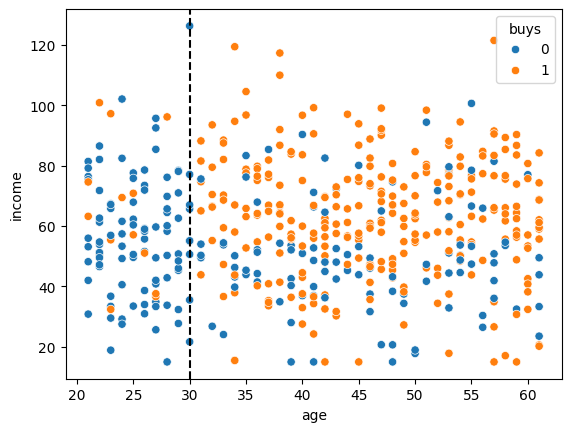

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

r = np.random.default_rng(262); n = 500
age = r.integers(21, 62, n); inc = r.normal(60, 20, n).clip(15)
p = np.where(age > 30, np.where(inc > 55, .9, .55), .1)
house = pd.DataFrame({"age": age, "income": inc, "buys": (r.random(n) < p).astype(int)})
print("Share of 30+ who buy :", house[house.age > 30].buys.mean().round(2))
print("Share of <=30 who buy:", house[house.age <= 30].buys.mean().round(2))
sns.scatterplot(data=house, x="age", y="income", hue="buys"); plt.axvline(30, ls="--", c="k"); plt.show()

In [2]:
def gini(y):
    p = y.value_counts(normalize=True); return 1 - (p ** 2).sum()
print("Root impurity (Gini):", round(gini(house.buys), 3))
left, right = house[house.age <= 30], house[house.age > 30]
w = (len(left) * gini(left.buys) + len(right) * gini(right.buys)) / len(house)
print("Weighted impurity after splitting on age<=30:", round(w, 3), "-> gain:", round(gini(house.buys) - w, 3))

Root impurity (Gini): 0.484
Weighted impurity after splitting on age<=30: 0.361 -> gain: 0.123


   depth  train_acc  test_acc  cv_acc
0      1      0.749     0.776   0.756
1      2      0.768     0.728   0.736
2      3      0.795     0.752   0.768
3      4      0.800     0.768   0.764
4      5      0.829     0.712   0.754
5      6      0.840     0.736   0.750
6      7      0.869     0.704   0.706
7      8      0.896     0.712   0.720


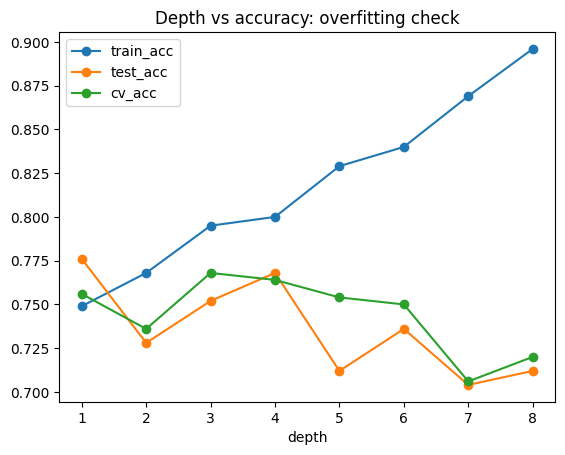

In [3]:
X, y = house[["age", "income"]], house["buys"]
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=.25, random_state=262, stratify=y)
rows = []
for d in range(1, 9):
    t = DecisionTreeClassifier(max_depth=d, random_state=262).fit(Xtr, ytr)
    rows.append((d, t.score(Xtr, ytr), t.score(Xte, yte), cross_val_score(DecisionTreeClassifier(max_depth=d, random_state=262), X, y, cv=5).mean()))
depth = pd.DataFrame(rows, columns=["depth", "train_acc", "test_acc", "cv_acc"]).round(3); print(depth)
depth.set_index("depth")[["train_acc", "test_acc", "cv_acc"]].plot(marker="o"); plt.title("Depth vs accuracy: overfitting check"); plt.show()

Chosen depth: 3
Test accuracy: 0.752
              precision    recall  f1-score   support

           0       0.68      0.75      0.71        51
           1       0.81      0.76      0.78        74

    accuracy                           0.75       125
   macro avg       0.75      0.75      0.75       125
weighted avg       0.76      0.75      0.75       125

|--- age <= 30.50
|   |--- income <= 95.90
|   |   |--- age <= 24.50
|   |   |   |--- class: 0
|   |   |--- age >  24.50
|   |   |   |--- class: 0
|   |--- income >  95.90
|   |   |--- income <= 101.44
|   |   |   |--- class: 1
|   |   |--- income >  101.44
|   |   |   |--- class: 0
|--- age >  30.50
|   |--- income <= 54.74
|   |   |--- income <= 38.30
|   |   |   |--- class: 1
|   |   |--- income >  38.30
|   |   |   |--- class: 0
|   |--- income >  54.74
|   |   |--- income <= 62.76
|   |   |   |--- class: 1
|   |   |--- income >  62.76
|   |   |   |--- class: 1

{'age': 0.592, 'income': 0.408}


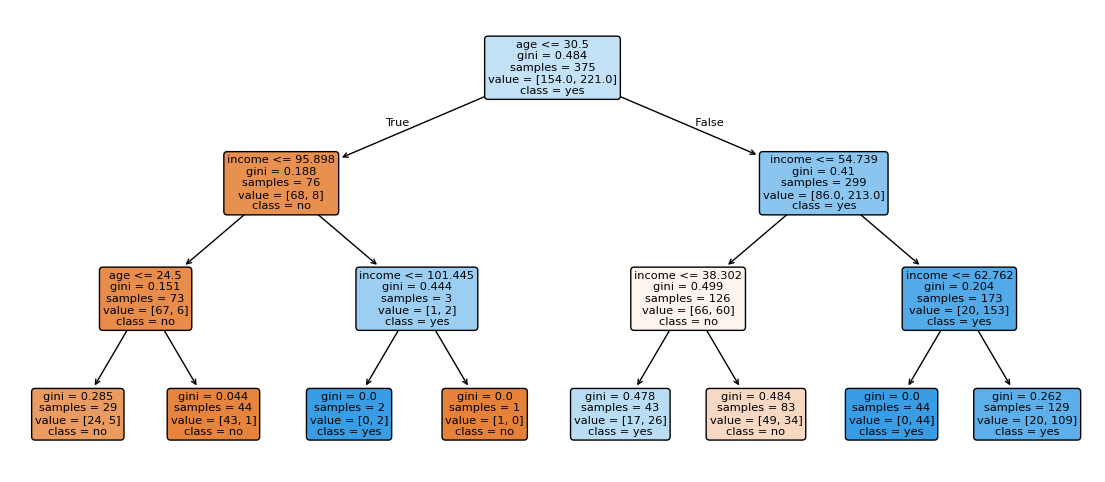

In [4]:
best = int(depth.loc[depth.cv_acc.idxmax(), "depth"]); print("Chosen depth:", best)
tree = DecisionTreeClassifier(max_depth=best, random_state=262).fit(Xtr, ytr); pred = tree.predict(Xte)
print("Test accuracy:", round(accuracy_score(yte, pred), 3)); print(classification_report(yte, pred))
print(export_text(tree, feature_names=["age", "income"]))
print(dict(zip(["age", "income"], tree.feature_importances_.round(3))))
plt.figure(figsize=(14, 6)); plot_tree(tree, feature_names=["age", "income"], class_names=["no", "yes"], filled=True, rounded=True); plt.show()

## Exercise 2 - Go out or stay in?
Outcome depends on the weather (and whether there's free time). With categorical inputs we one-hot encode, then read the learned rules.

Training accuracy: 1.0
|--- free_time <= 0.50
|   |--- class: stay in
|--- free_time >  0.50
|   |--- weather_rainy <= 0.50
|   |   |--- class: go out
|   |--- weather_rainy >  0.50
|   |   |--- class: stay in



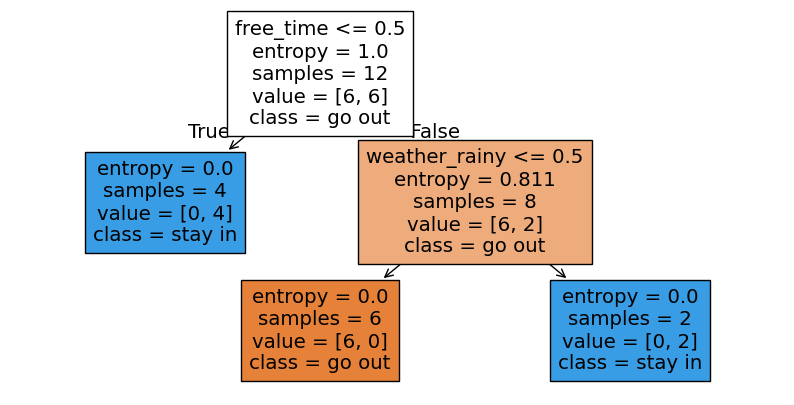

In [5]:
plans = pd.DataFrame({
    "weather":   ["sunny", "sunny", "rainy", "rainy", "sunny", "rainy", "cloudy", "cloudy", "sunny", "rainy", "cloudy", "sunny"],
    "free_time": [1, 1, 1, 0, 1, 1, 1, 0, 0, 0, 1, 1],
    "decision":  ["go out", "go out", "stay in", "stay in", "go out", "stay in", "go out", "stay in", "stay in", "stay in", "go out", "go out"]})
Xp = pd.get_dummies(plans[["weather", "free_time"]]); yp = plans["decision"]
tp = DecisionTreeClassifier(criterion="entropy", random_state=262).fit(Xp, yp)
print("Training accuracy:", tp.score(Xp, yp)); print(export_text(tp, feature_names=list(Xp.columns)))
plt.figure(figsize=(10, 5)); plot_tree(tp, feature_names=list(Xp.columns), class_names=list(tp.classes_), filled=True); plt.show()

In [6]:
def decide(weather, free_time):
    row = pd.DataFrame([{c: 0 for c in Xp.columns}]); row["free_time"] = free_time
    if f"weather_{weather}" in row: row[f"weather_{weather}"] = 1
    return tp.predict(row)[0]
for w_, f_ in [("sunny", 1), ("rainy", 1), ("cloudy", 0)]:
    print(f"{w_:7s} free_time={f_} ->", decide(w_, f_))

sunny   free_time=1 -> go out
rainy   free_time=1 -> stay in
cloudy  free_time=0 -> stay in


### Conclusion
The tree rediscovers `age` as the first split. Controlling depth via cross-validation prevents memorising noise, and entropy/Gini both give readable if-then rules for the weather decision.